# Glider Europa isär?

Två frågor:

1. Var i Europa (EU) är det svårast att få jobb i dag?
2. Har länder med välutbildad befolkning lägre arbetslöshet?

Notebooken läser bara från databasen. Datan hämtas först med `python kor.py`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

from db import engine

arbetsloshet = pd.read_sql("SELECT * FROM arbetsloshet", engine)
utbildning = pd.read_sql("SELECT * FROM utbildning", engine)

# EU:s 27 länder. Eurostat använder EL för Grekland.
LANDER = {
    "AT": "Österrike", "BE": "Belgien", "BG": "Bulgarien", "CY": "Cypern", "CZ": "Tjeckien",
    "DE": "Tyskland", "DK": "Danmark", "EE": "Estland", "EL": "Grekland", "ES": "Spanien",
    "FI": "Finland", "FR": "Frankrike", "HR": "Kroatien", "HU": "Ungern", "IE": "Irland",
    "IT": "Italien", "LT": "Litauen", "LU": "Luxemburg", "LV": "Lettland", "MT": "Malta",
    "NL": "Nederländerna", "PL": "Polen", "PT": "Portugal", "RO": "Rumänien", "SE": "Sverige",
    "SI": "Slovenien", "SK": "Slovakien",
}

## Datakvalitet

In [2]:
for namn, tabell in [("arbetsloshet", arbetsloshet), ("utbildning", utbildning)]:
    eu = tabell[tabell.land.isin(LANDER)]
    print(namn.upper())
    print("  rader i hela tabellen:", len(tabell))
    print("  saknade värden i hela tabellen:", tabell.varde.isna().sum())
    print("  EU-länder:", eu.land.nunique())
    print("  saknade värden för EU-länderna:", eu.varde.isna().sum())
    print("  dubbletter:", eu.duplicated(["land", "ar"]).sum())
    print("  lägsta och högsta värde:", eu.varde.min(), "och", eu.varde.max())

ARBETSLOSHET
  rader i hela tabellen: 851
  saknade värden i hela tabellen: 233
  EU-länder: 27
  saknade värden för EU-länderna: 152
  dubbletter: 0
  lägsta och högsta värde: 1.8 och 25.6
UTBILDNING
  rader i hela tabellen: 988
  saknade värden i hela tabellen: 75
  EU-länder: 27
  saknade värden för EU-länderna: 6
  dubbletter: 0
  lägsta och högsta värde: 5.4 och 58.7


In [3]:
# Senaste året där alla 27 länder har värden i båda tabellerna
SQL = """
SELECT a.land, a.ar, a.varde AS arbetsloshet, u.varde AS utbildning
FROM arbetsloshet AS a
JOIN utbildning AS u ON a.land = u.land AND a.ar = u.ar
WHERE a.varde IS NOT NULL AND u.varde IS NOT NULL
"""
alla = pd.read_sql(SQL, engine)
alla = alla[alla.land.isin(LANDER)]
antal = alla.groupby("ar").land.count()
AR = int(antal[antal == 27].index.max())

data = alla[alla.ar == AR].set_index("land")
data["namn"] = data.index.map(LANDER)
print("År som används:", AR)
print("Antal länder:", len(data))

År som används: 2025
Antal länder: 27


**Vad jag såg:**

- Alla 27 EU-länder finns i båda tabellerna. Inga dubbletter.
- Det saknas värden för EU-länderna i gamla år (152 för arbetslöshet, 6 för utbildning), men inga för 2025.
- Båda frågorna använder samma år: 2025.
- Enheten är procent i båda. Arbetslöshet: procent av arbetskraften, 25-74 år. Utbildning: procent med
  högskoleutbildning, 25-64 år. Åldrarna slutar olika, och det är en begränsning.

## Fråga 1: Var är det svårast att få jobb?

Högst: Spanien 9.4 %
Lägst: Tjeckien 2.3 %
Median: 5.0 %


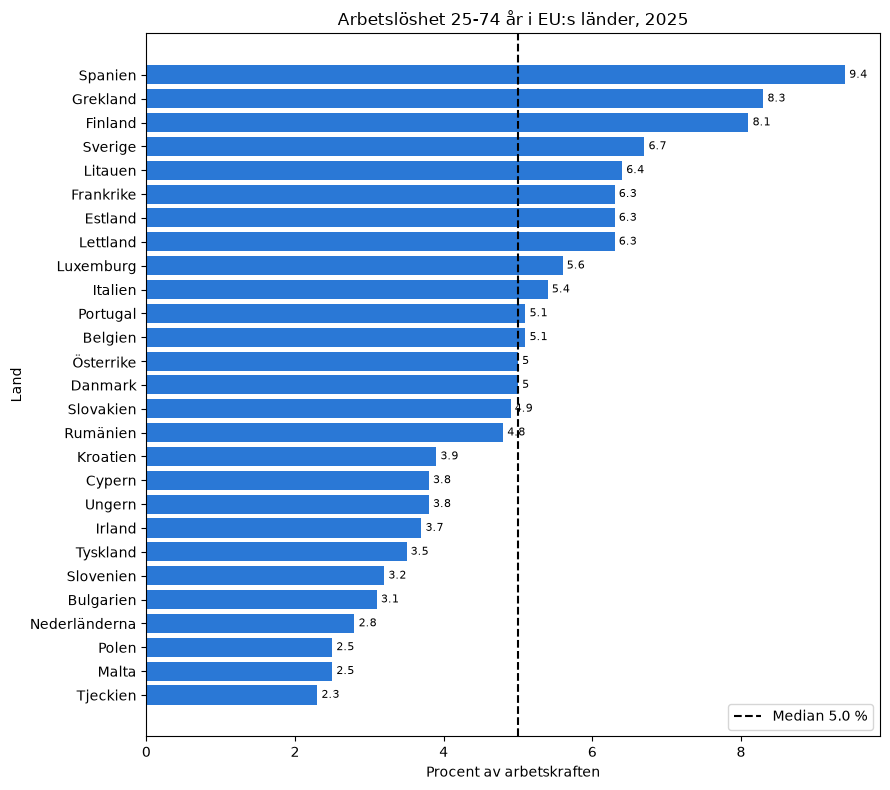

In [4]:
sorterad = data.sort_values("arbetsloshet")
median = data.arbetsloshet.median()
hogst = sorterad.iloc[-1]
lagst = sorterad.iloc[0]
print(f"Högst: {hogst.namn} {hogst.arbetsloshet} %")
print(f"Lägst: {lagst.namn} {lagst.arbetsloshet} %")
print(f"Median: {median} %")

plt.figure(figsize=(9, 8))
staplar = plt.barh(sorterad.namn, sorterad.arbetsloshet, color="#2a78d6")
plt.bar_label(staplar, padding=3, fontsize=8)
plt.axvline(median, color="black", linestyle="--", label=f"Median {median} %")
plt.title(f"Arbetslöshet 25-74 år i EU:s länder, {AR}")
plt.xlabel("Procent av arbetskraften")
plt.ylabel("Land")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

**Vad visar det?**

- Svårast var det i Spanien (9,4 %), sedan Grekland (8,3 %) och Finland (8,1 %). Sverige kommer fyra (6,7 %).
- Lägst var Tjeckien (2,3 %).
- Medianen är 5,0 %, alltså mittenvärdet. 12 länder ligger över, 2 har exakt 5,0 % och 13 ligger under.

Det här är en beskrivning. Diagrammet visar var arbetslösheten är hög, inte varför.
Arbetslöshet är ett mått på hur svårt det är att få jobb, men inte det enda.

### Tabeller för fråga 1

In [5]:
pd.DataFrame({
    "Mått": ["Högst", "Lägst", "Median"],
    "Land": [hogst.namn, lagst.namn, "-"],
    "Arbetslöshet %": [hogst.arbetsloshet, lagst.arbetsloshet, median],
}).set_index("Mått")

,Land,Arbetslöshet %
Mått,,
Högst,Spanien,9.4
Lägst,Tjeckien,2.3
Median,-,5.0


In [6]:
# Alla länder, högst arbetslöshet först
tabell = data[["namn", "arbetsloshet", "utbildning"]].sort_values("arbetsloshet", ascending=False)
tabell.columns = ["Land", "Arbetslöshet %", "Högskoleutbildade %"]
tabell

,Land,Arbetslöshet %,Högskoleutbildade %
land,,,
ES,Spanien,9.4,42.4
EL,Grekland,8.3,34.9
FI,Finland,8.1,42.7
SE,Sverige,6.7,50.8
LT,Litauen,6.4,49.9
EE,Estland,6.3,42.1
LV,Lettland,6.3,40.7
FR,Frankrike,6.3,44.8
LU,Luxemburg,5.6,55.7


## Fråga 2: Har länder med fler välutbildade lägre arbetslöshet?

- **Spearman-korrelation** jämför ländernas rangordning. Värdet går från -1 till 1. 0 betyder inget samband.
- **Linjär regression** drar en rak linje genom punkterna. Lutningen visar hur arbetslösheten ändras
  när andelen utbildade är 1 procentenhet högre.
- **95 % konfidensintervall** visar hur osäker lutningen är.

In [7]:
rho, p = stats.spearmanr(data.utbildning, data.arbetsloshet)
modell = smf.ols("arbetsloshet ~ utbildning", data=data).fit()
lutning = modell.params["utbildning"]
ki_lag, ki_hog = modell.conf_int().loc["utbildning"]

print(f"Spearman rho: {rho:.2f} (p = {p:.2f})")
print(f"Lutning: {lutning:.3f}")
print(f"95 % konfidensintervall: {ki_lag:.3f} till {ki_hog:.3f}")
print(f"R2: {modell.rsquared:.3f}")

Spearman rho: 0.26 (p = 0.20)
Lutning: 0.033
95 % konfidensintervall: -0.046 till 0.112
R2: 0.029


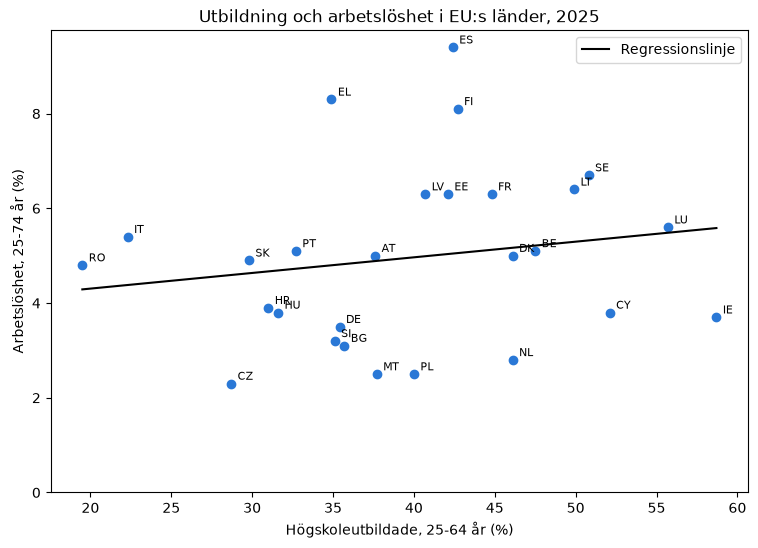

In [8]:
plt.figure(figsize=(9, 6))
plt.scatter(data.utbildning, data.arbetsloshet, color="#2a78d6")
for land, rad in data.iterrows():
    plt.text(rad.utbildning + 0.4, rad.arbetsloshet + 0.08, land, fontsize=8)

x = pd.DataFrame({"utbildning": [data.utbildning.min(), data.utbildning.max()]})
plt.plot(x.utbildning, modell.predict(x), color="black", label="Regressionslinje")
plt.title(f"Utbildning och arbetslöshet i EU:s länder, {AR}")
plt.xlabel("Högskoleutbildade, 25-64 år (%)")
plt.ylabel("Arbetslöshet, 25-74 år (%)")
plt.ylim(0)
plt.legend()
plt.show()

### Tabell för fråga 2

In [9]:
pd.DataFrame({
    "Mått": ["Spearman rho", "Lutning", "95 % intervall, från", "95 % intervall, till", "R2"],
    "Värde": [rho, lutning, ki_lag, ki_hog, modell.rsquared],
}).set_index("Mått").round(3)

,Värde
Mått,
Spearman rho,0.257
Lutning,0.033
"95 % intervall, från",-0.046
"95 % intervall, till",0.112
R2,0.029


**Vad visar det?**

- Spearman är 0,26. Det är ett svagt samband, och det går åt andra hållet än man kanske tror.
- Lutningen är 0,033. Konfidensintervallet går från -0,046 till 0,112 och innehåller 0.
- R2 är 0,029, så utbildningen förklarar ungefär 3 % av skillnaderna.

**Svar: nej, jag ser inget tydligt samband.** Det betyder inte att det säkert saknas samband.

Det är ett samband mellan länder, inte en orsak. Det säger inget om en enskild persons chans att
få jobb. Andra saker kan också påverka arbetslösheten.